<a href="https://colab.research.google.com/github/akatwrk/DeeplearningExp/blob/main/exp_8a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
import os
import pandas as pd

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Load powerconsumption.csv directly from your 'deeplearning' folder
csv_path = "/content/drive/MyDrive/deeplearning/powerconsumption.csv"
df = pd.read_csv(csv_path)

print(df.shape)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(52416, 9)


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [3]:

print(df.head())
print(df.info())
print(df.columns)
print(df.isnull().sum())

        Datetime  Temperature  Humidity  WindSpeed  GeneralDiffuseFlows  \
0  1/1/2017 0:00        6.559      73.8      0.083                0.051   
1  1/1/2017 0:10        6.414      74.5      0.083                0.070   
2  1/1/2017 0:20        6.313      74.5      0.080                0.062   
3  1/1/2017 0:30        6.121      75.0      0.083                0.091   
4  1/1/2017 0:40        5.921      75.7      0.081                0.048   

   DiffuseFlows  PowerConsumption_Zone1  PowerConsumption_Zone2  \
0         0.119             34055.69620             16128.87538   
1         0.085             29814.68354             19375.07599   
2         0.100             29128.10127             19006.68693   
3         0.096             28228.86076             18361.09422   
4         0.085             27335.69620             17872.34043   

   PowerConsumption_Zone3  
0             20240.96386  
1             20131.08434  
2             19668.43373  
3             18899.27711  
4     

In [4]:
df["Datetime"] = pd.to_datetime(df["Datetime"])

df = df.sort_values("Datetime")

df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [5]:
target = df[["PowerConsumption_Zone1"]]

target.head()

,PowerConsumption_Zone1
0,34055.69620
1,29814.68354
2,29128.10127
3,28228.86076
4,27335.69620


In [6]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(target)
train_size = int(len(scaled_data) * 0.8)

train = scaled_data[:train_size]
test = scaled_data[train_size:]

In [7]:
import numpy as np

def create_sequences(data, lookback):
    X = []
    y = []

    for i in range(len(data) - lookback):
        X.append(data[i:i+lookback])
        y.append(data[i+lookback])

    return np.array(X), np.array(y)

lookback = 30

X_train, y_train = create_sequences(train, lookback)
X_test, y_test = create_sequences(test, lookback)

In [8]:

print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

(41902, 30, 1)
(41902, 1)
(10454, 30, 1)
(10454, 1)


In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

lstm_model = Sequential([

    LSTM(
        64,
        input_shape=(30,1)
    ),

    Dense(32, activation="relu"),

    Dense(1)

])

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    )

]

In [11]:
history_lstm = lstm_model.fit(

    X_train,
    y_train,

    validation_data=(X_test,y_test),

    epochs=10,

    batch_size=32,

    callbacks=callbacks

)

Epoch 1/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - loss: 0.0019 - mae: 0.0221 - val_loss: 2.1094e-04 - val_mae: 0.0089 - learning_rate: 0.0010
Epoch 2/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 2.2438e-04 - mae: 0.0099 - val_loss: 1.3784e-04 - val_mae: 0.0083 - learning_rate: 0.0010
Epoch 3/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 1.6947e-04 - mae: 0.0086 - val_loss: 1.0598e-04 - val_mae: 0.0070 - learning_rate: 0.0010
Epoch 4/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 1.6191e-04 - mae: 0.0085 - val_loss: 1.0498e-04 - val_mae: 0.0067 - learning_rate: 0.0010
Epoch 5/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 1.5732e-04 - mae: 0.0083 - val_loss: 1.6070e-04 - val_mae: 0.0101 - learning_rate: 0.0010
Epoch 6/10
1309/1310 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.6265e-04 - mae: 0.0081
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 1.4895e-04 - mae: 0.0080 

In [18]:
loss_lstm, mae_lstm = lstm_model.evaluate(X_test, y_test, verbose=0)

print("LSTM Loss :", loss_lstm)
print("LSTM MAE  :", mae_lstm)

LSTM Loss : 9.267945279134437e-05
LSTM MAE  : 0.006311370991170406


In [19]:
from tensorflow.keras.layers import Bidirectional, LSTM, Dense
from tensorflow.keras.models import Sequential
bilstm_model = Sequential([
Bidirectional(
LSTM(64),
input_shape=(30,1)
),
Dense(32, activation="relu"),
Dense(1)
])
bilstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,953 (148.25 KB)

 Trainable params: 37,953 (148.25 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
bilstm_model.compile(
optimizer="adam",
loss="mse",
metrics=["mae"]
)
history_bilstm = bilstm_model.fit(
X_train,
y_train,
validation_data=(X_test, y_test),
epochs=10,
batch_size=32,
callbacks=callbacks
)

Epoch 1/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - loss: 0.0026 - mae: 0.0247 - val_loss: 2.3003e-04 - val_mae: 0.0094 - learning_rate: 0.0010
Epoch 2/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - loss: 2.5184e-04 - mae: 0.0107 - val_loss: 1.4352e-04 - val_mae: 0.0077 - learning_rate: 0.0010
Epoch 3/10
1309/1310 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.8309e-04 - mae: 0.0094
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - loss: 1.8497e-04 - mae: 0.0092 - val_loss: 1.1234e-04 - val_mae: 0.0072 - learning_rate: 0.0010
Epoch 4/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - loss: 1.4754e-04 - mae: 0.0080 - val_loss: 9.7366e-05 - val_mae: 0.0064 - learning_rate: 5.0000e-04
Epoch 5/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - loss: 1.4427e-04 - mae: 0.0079 - val_loss: 1.0522e-04 - val_mae: 0.0073 - learning_rate: 5.0000e-04


In [21]:
print(callbacks)

[<keras.src.callbacks.early_stopping.EarlyStopping object at 0x7af8ee975940>, <keras.src.callbacks.reduce_lr_on_plateau.ReduceLROnPlateau object at 0x7af8ee9752b0>]


In [22]:
loss_bilstm, mae_bilstm = bilstm_model.evaluate(X_test, y_test, verbose=0)

print("Bidirectional LSTM Loss:", loss_bilstm)
print("Bidirectional LSTM MAE :", mae_bilstm)

Bidirectional LSTM Loss: 0.0002300308260601014
Bidirectional LSTM MAE : 0.009398788213729858


In [23]:
comparison = pd.DataFrame({

    "Model":[
        "LSTM",
        "Bidirectional LSTM"
    ],

    "Loss":[
        loss_lstm,
        loss_bilstm
    ],

    "MAE":[
        mae_lstm,
        mae_bilstm
    ]

})


327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


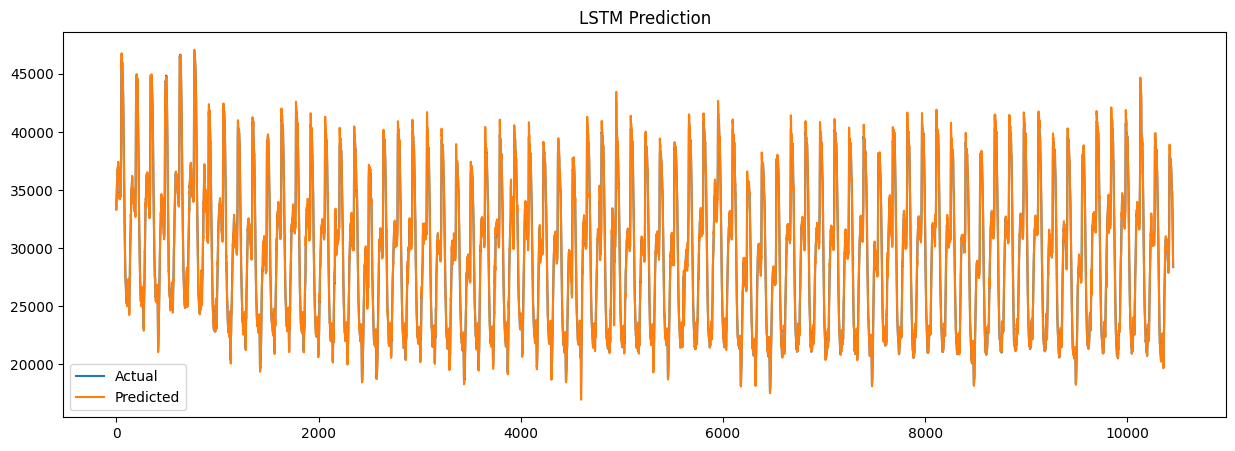

In [25]:
import matplotlib.pyplot as plt

pred_lstm = lstm_model.predict(X_test)
pred_lstm = scaler.inverse_transform(pred_lstm)
actual = scaler.inverse_transform(y_test)

plt.figure(figsize=(15,5))
plt.plot(actual, label="Actual")
plt.plot(pred_lstm, label="Predicted")
plt.legend()
plt.title("LSTM Prediction")
plt.show()

327/327 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


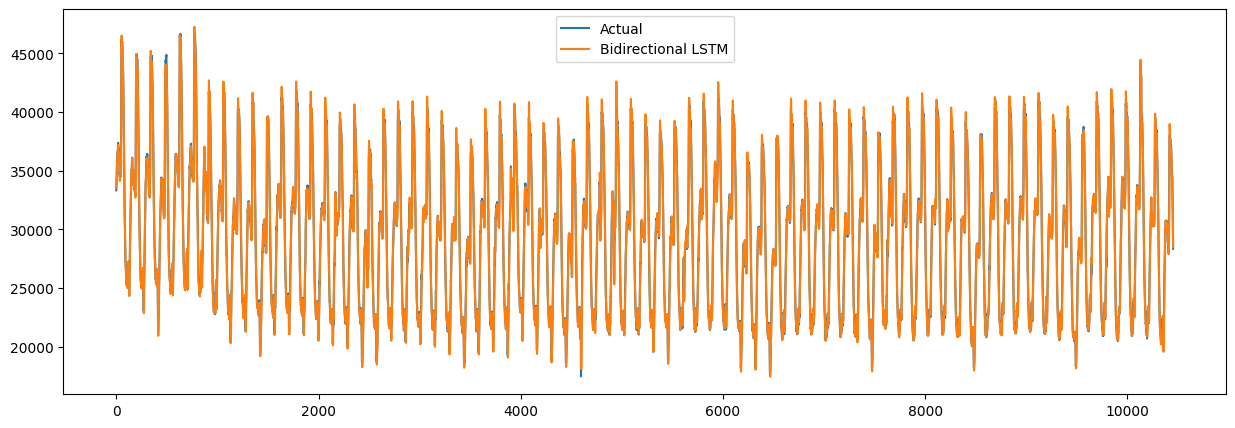

In [26]:
pred_bilstm = bilstm_model.predict(X_test)
pred_bilstm = scaler.inverse_transform(pred_bilstm)
plt.figure(figsize=(15,5))
plt.plot(actual,label="Actual")
plt.plot(pred_bilstm,label="Bidirectional LSTM")
plt.legend()
plt.show()

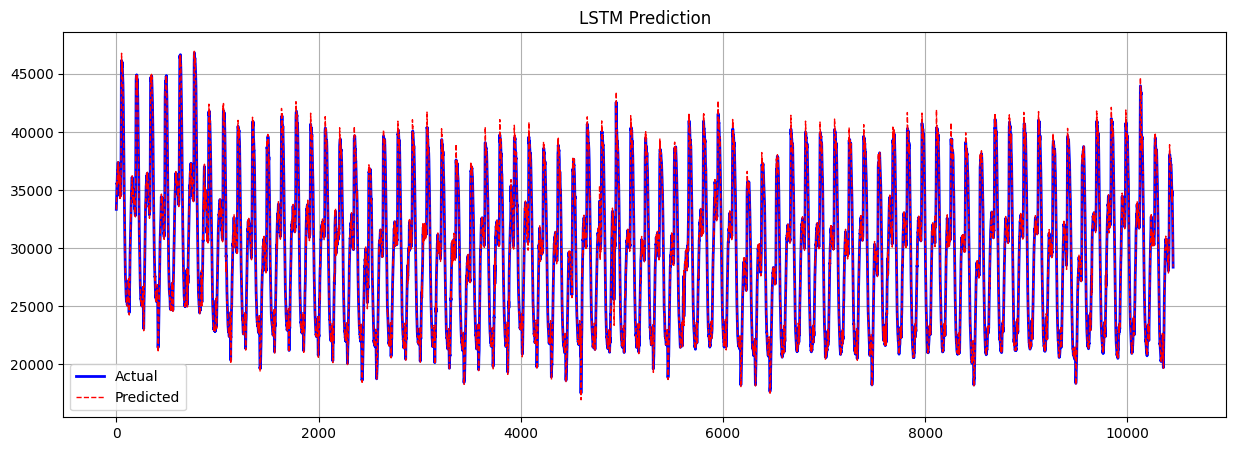

In [27]:
plt.figure(figsize=(15,5))
plt.plot(actual, label="Actual", color="blue", linewidth=2)
plt.plot(pred_lstm,
label="Predicted",
color="red",
linestyle="--",
linewidth=1)
plt.legend()
plt.title("LSTM Prediction")
plt.grid(True)
plt.show()